<div dir="rtl">

# 01 · EDA: תאונות דרכים עם נפגעים 2024

**הדאטה:** קובץ פרטני של הלמ"ס, `h20241331data.csv` מ־data.gov.il. כל שורה היא תאונה אחת.
**המטרה:** לחזות את `HUMRAT_TEUNA` (חומרת התאונה): 1 = קטלנית, 2 = קשה, 3 = קלה.

> כל תא קוד במחברת נכתב בעזרת Claude, ולכן מסומן `### CODE BY CLAUDE ###` לפי הנחיות המרצה.
> הפירוש של הקודים לקוח ממילון הקודים של הלמ"ס (`data/raw/codes_dictionary_subset.csv`).

</div>

In [1]:
### CODE BY CLAUDE ###
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # כדי שאפשר יהיה לייבא את src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (load_raw, add_features, get_xy, build_preprocessor, FIGURES,
                      RANDOM_STATE, TARGET, SEVERITY_NAMES, CATEGORICAL, NUMERIC, BINARY,
                      label, COLUMN_NAMES)

sns.set_theme(style="whitegrid")
FIGURES.mkdir(exist_ok=True)
SEV_ORDER = ["קטלנית", "קשה", "קלה"]
SEV_COLORS = ["#a3262c", "#e08a2c", "#7a8aa0"]
####

<div dir="rtl">

**מאיזה שיעור כל דבר:** טיפול בדאטה לא מאוזן, `stratify`, Data Leakage, Macro F1 (שיעור 1) · Scaling ו־One-hot (שיעור 2) · כפילויות, השלמת חסרים, נרמול ו־PCA (שיעור 3).
שאר המחברת היא תיאור הדאטה בטבלאות ובגרפים פשוטים (אחוזים וספירות).

</div>

<div dir="rtl">

## 1. גודל הדאטה ובדיקת הדרישות
המרצה דורש יותר מ־140 שורות ולפחות 15 פיצ'רים משמעותיים.

</div>

In [2]:
### CODE BY CLAUDE ###
df = load_raw()
print("שורות, עמודות:", df.shape)
df.head()
####

שורות, עמודות: (8315, 45)


,pk_teuna_fikt,sug_tik,THUM_GEOGRAFI,SUG_DEREH,SEMEL_YISHUV,REHOV1,REHOV2,BAYIT,ZOMET_IRONI,KVISH1,...,MEKOM_HAZIYA,KIVUN_HAZIYA,MAHOZ,NAFA,EZOR_TIVI,MAAMAD_MINIZIPALI,ZURAT_ISHUV,STATUS_IGUN,X,Y
0,2023096257,1,1,1,8600,1505.0,1619.0,NaN,160223.0,NaN,...,3,9,5,51,512,0.0,14,1,184053.0,663193.0
1,2024000009,1,1,2,3000,5403.0,NaN,41.0,NaN,NaN,...,0,9,1,11,111,0.0,12,1,221817.0,628497.0
2,2024000034,1,1,2,7900,148.0,NaN,2.0,NaN,NaN,...,0,9,4,42,422,0.0,13,3,190310.0,668268.0
3,2024000069,1,1,4,0,NaN,NaN,NaN,NaN,2411.0,...,0,9,6,62,622,99.0,99,3,168970.0,580206.0
4,2024000076,1,1,4,0,NaN,NaN,NaN,NaN,2.0,...,0,9,4,41,411,99.0,99,1,188598.0,695708.0


In [3]:
### CODE BY CLAUDE ###
# כמה ערכים שונים יש בכל עמודה, וכמה חסר
profile = pd.DataFrame({
    "ערכים שונים": df.nunique(),
    "% חסר": (df.isna().mean() * 100).round(1),
}).sort_values("ערכים שונים")
profile
####

,ערכים שונים,% חסר
sug_tik,1,0.0
SHNAT_TEUNA,1,0.0
THUM_GEOGRAFI,2,0.0
YOM_LAYLA,2,0.0
HUMRAT_TEUNA,3,0.0
KIVUN_HAZIYA,3,0.0
SUG_DEREH,4,0.0
SUG_YOM,4,0.0
TKINUT,5,0.0
SIMUN_TIMRUR,5,0.0


<div dir="rtl">

**מה רואים:**
- `sug_tik` ו־`SHNAT_TEUNA` עם ערך אחד בלבד, ו־`pk_teuna_fikt` (מספר התאונה) הוא מזהה, ערך שונה בכל שורה. לא נושאים מידע, ולכן נזרקים.
- עמודות כמו רחוב, צומת, כביש וק"מ הן **מזהים** עם מאות ערכים שונים. One-hot שלהן היה יוצר אלפי עמודות. הן נשארות בדאטה ונבדקות בסעיף 8, אבל לא נכנסות למודל.
- ההחלטה על כל עמודה (פגישת הצוות, 3.11) מופיעה בטבלה בסעיף 8.

</div>

<div dir="rtl">

## 2. משתנה המטרה: הדאטה לא מאוזן (שיעור 1)

</div>

              מספר תאונות     %
HUMRAT_TEUNA                   
קטלנית                405   4.9
קשה                  2452  29.5
קלה                  5458  65.6


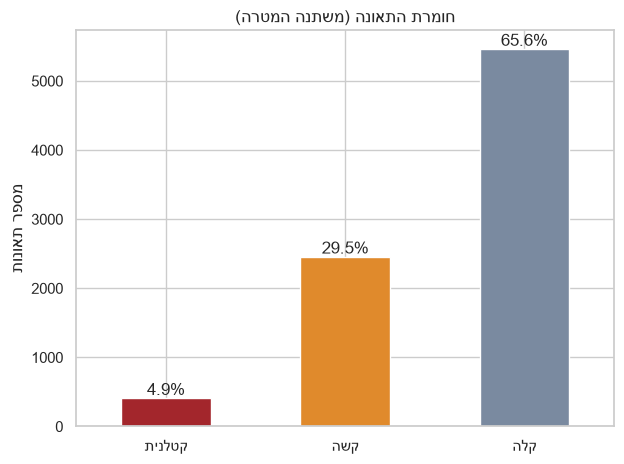

In [4]:
### CODE BY CLAUDE ###
counts = df[TARGET].map(SEVERITY_NAMES).value_counts().reindex(SEV_ORDER)
pct = (counts / counts.sum() * 100).round(1)
print(pd.DataFrame({"מספר תאונות": counts, "%": pct}))

ax = counts.plot.bar(color=SEV_COLORS, rot=0)
for p, v in zip(ax.patches, pct):
    ax.annotate(f"{v}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("חומרת התאונה (משתנה המטרה)")
ax.set_xlabel("")
ax.set_ylabel("מספר תאונות")
plt.tight_layout(); plt.savefig(FIGURES / "01_target_distribution.png", dpi=150); plt.show()
####

<div dir="rtl">

**מסקנה:** רק כ־4.9% מהתאונות קטלניות. מודל שעונה תמיד "קלה" יקבל Accuracy של 66% בלי ללמוד כלום.
לכן בהמשך: `stratify` בפיצול, מדדים כמו F1-macro ו־Recall של "קטלנית", והשוואה של שיטות איזון (class_weight, SMOTE).

</div>

<div dir="rtl">

## 3. ערכים חסרים: חוסר מבני
השאלה: האם החוסר אקראי, או שיש לו סיבה?

</div>

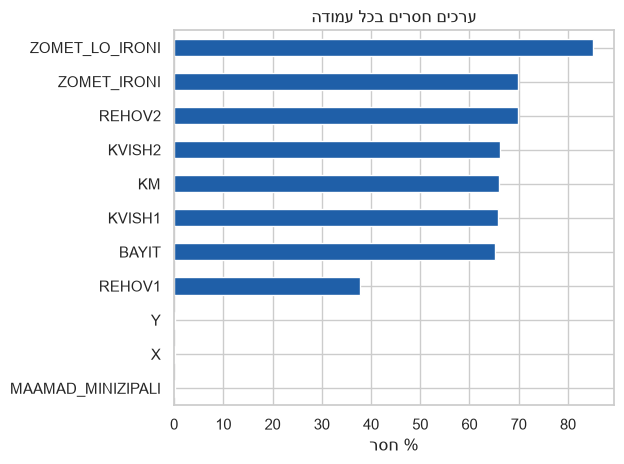

In [5]:
### CODE BY CLAUDE ###
missing = df.isna().mean().mul(100)
missing = missing[missing > 0].sort_values()
ax = missing.plot.barh(color="#1f5fa8")
ax.set_xlabel("% חסר"); ax.set_title("ערכים חסרים בכל עמודה")
plt.tight_layout(); plt.savefig(FIGURES / "02_missing_values.png", dpi=150); plt.show()
####

                     REHOV1  ZOMET_IRONI  KVISH1     KM  ZOMET_LO_IRONI
עירונית בצומת           0.0          1.0   100.0  100.0           100.0
עירונית לא בצומת        9.0        100.0   100.0  100.0           100.0
לא-עירונית בצומת      100.0        100.0     0.0    0.0             0.0
לא-עירונית לא בצומת   100.0        100.0     1.0    3.0           100.0


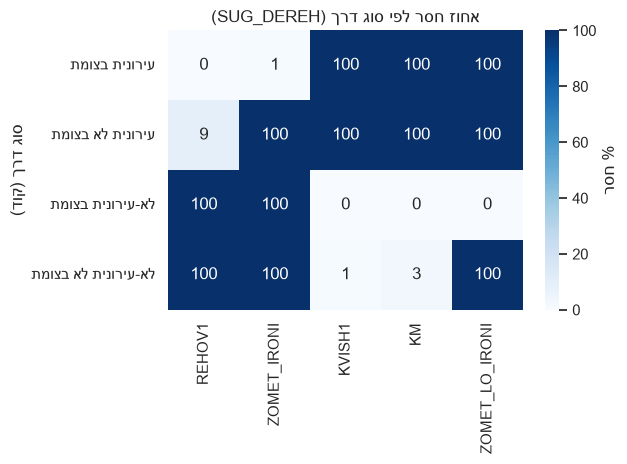

In [6]:
### CODE BY CLAUDE ###
# SUG_DEREH: ‏1–2 = דרך עירונית, 3–4 = דרך בין־עירונית (לאמת במילון)
cols = ["REHOV1", "ZOMET_IRONI", "KVISH1", "KM", "ZOMET_LO_IRONI"]
by_road = df.groupby("SUG_DEREH")[cols].apply(lambda g: g.isna().mean().mul(100).round(0))
by_road.index = [label("SUG_DEREH", c) for c in by_road.index]   # שמות מהמילון במקום קודים
print(by_road)
sns.heatmap(by_road, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% חסר"})
plt.title("אחוז חסר לפי סוג דרך (SUG_DEREH)")
plt.ylabel("סוג דרך (קוד)")
plt.tight_layout(); plt.savefig(FIGURES / "03_missing_by_road_type.png", dpi=150); plt.show()
####

<div dir="rtl">

**מסקנה:** החוסר **מבני**, לא טעות: בתאונה בעיר (SUG_DEREH 1–2) אין מספר כביש וק"מ, ובתאונה בין־עירונית (3–4) אין רחוב.
לכן לא "משלימים" אותם בממוצע. במקום זה יוצרים דגלים: `HAS_STREET`, `HAS_ROAD_NUMBER`.
ואת `SUG_DEREH` עצמה מפצלים לשני דגלים (החלטת הצוות): `URBAN` (עירוני או לא) ו־`JUNCTION` (בצומת או לא).

</div>

<div dir="rtl">

## 4. חומרה מול הפיצ'רים
בכל גרף: **אחוז** התאונות הקטלניות והקשות בכל קטגוריה. אחוז ולא ספירה, כי הקטגוריות בגדלים שונים מאוד.

</div>

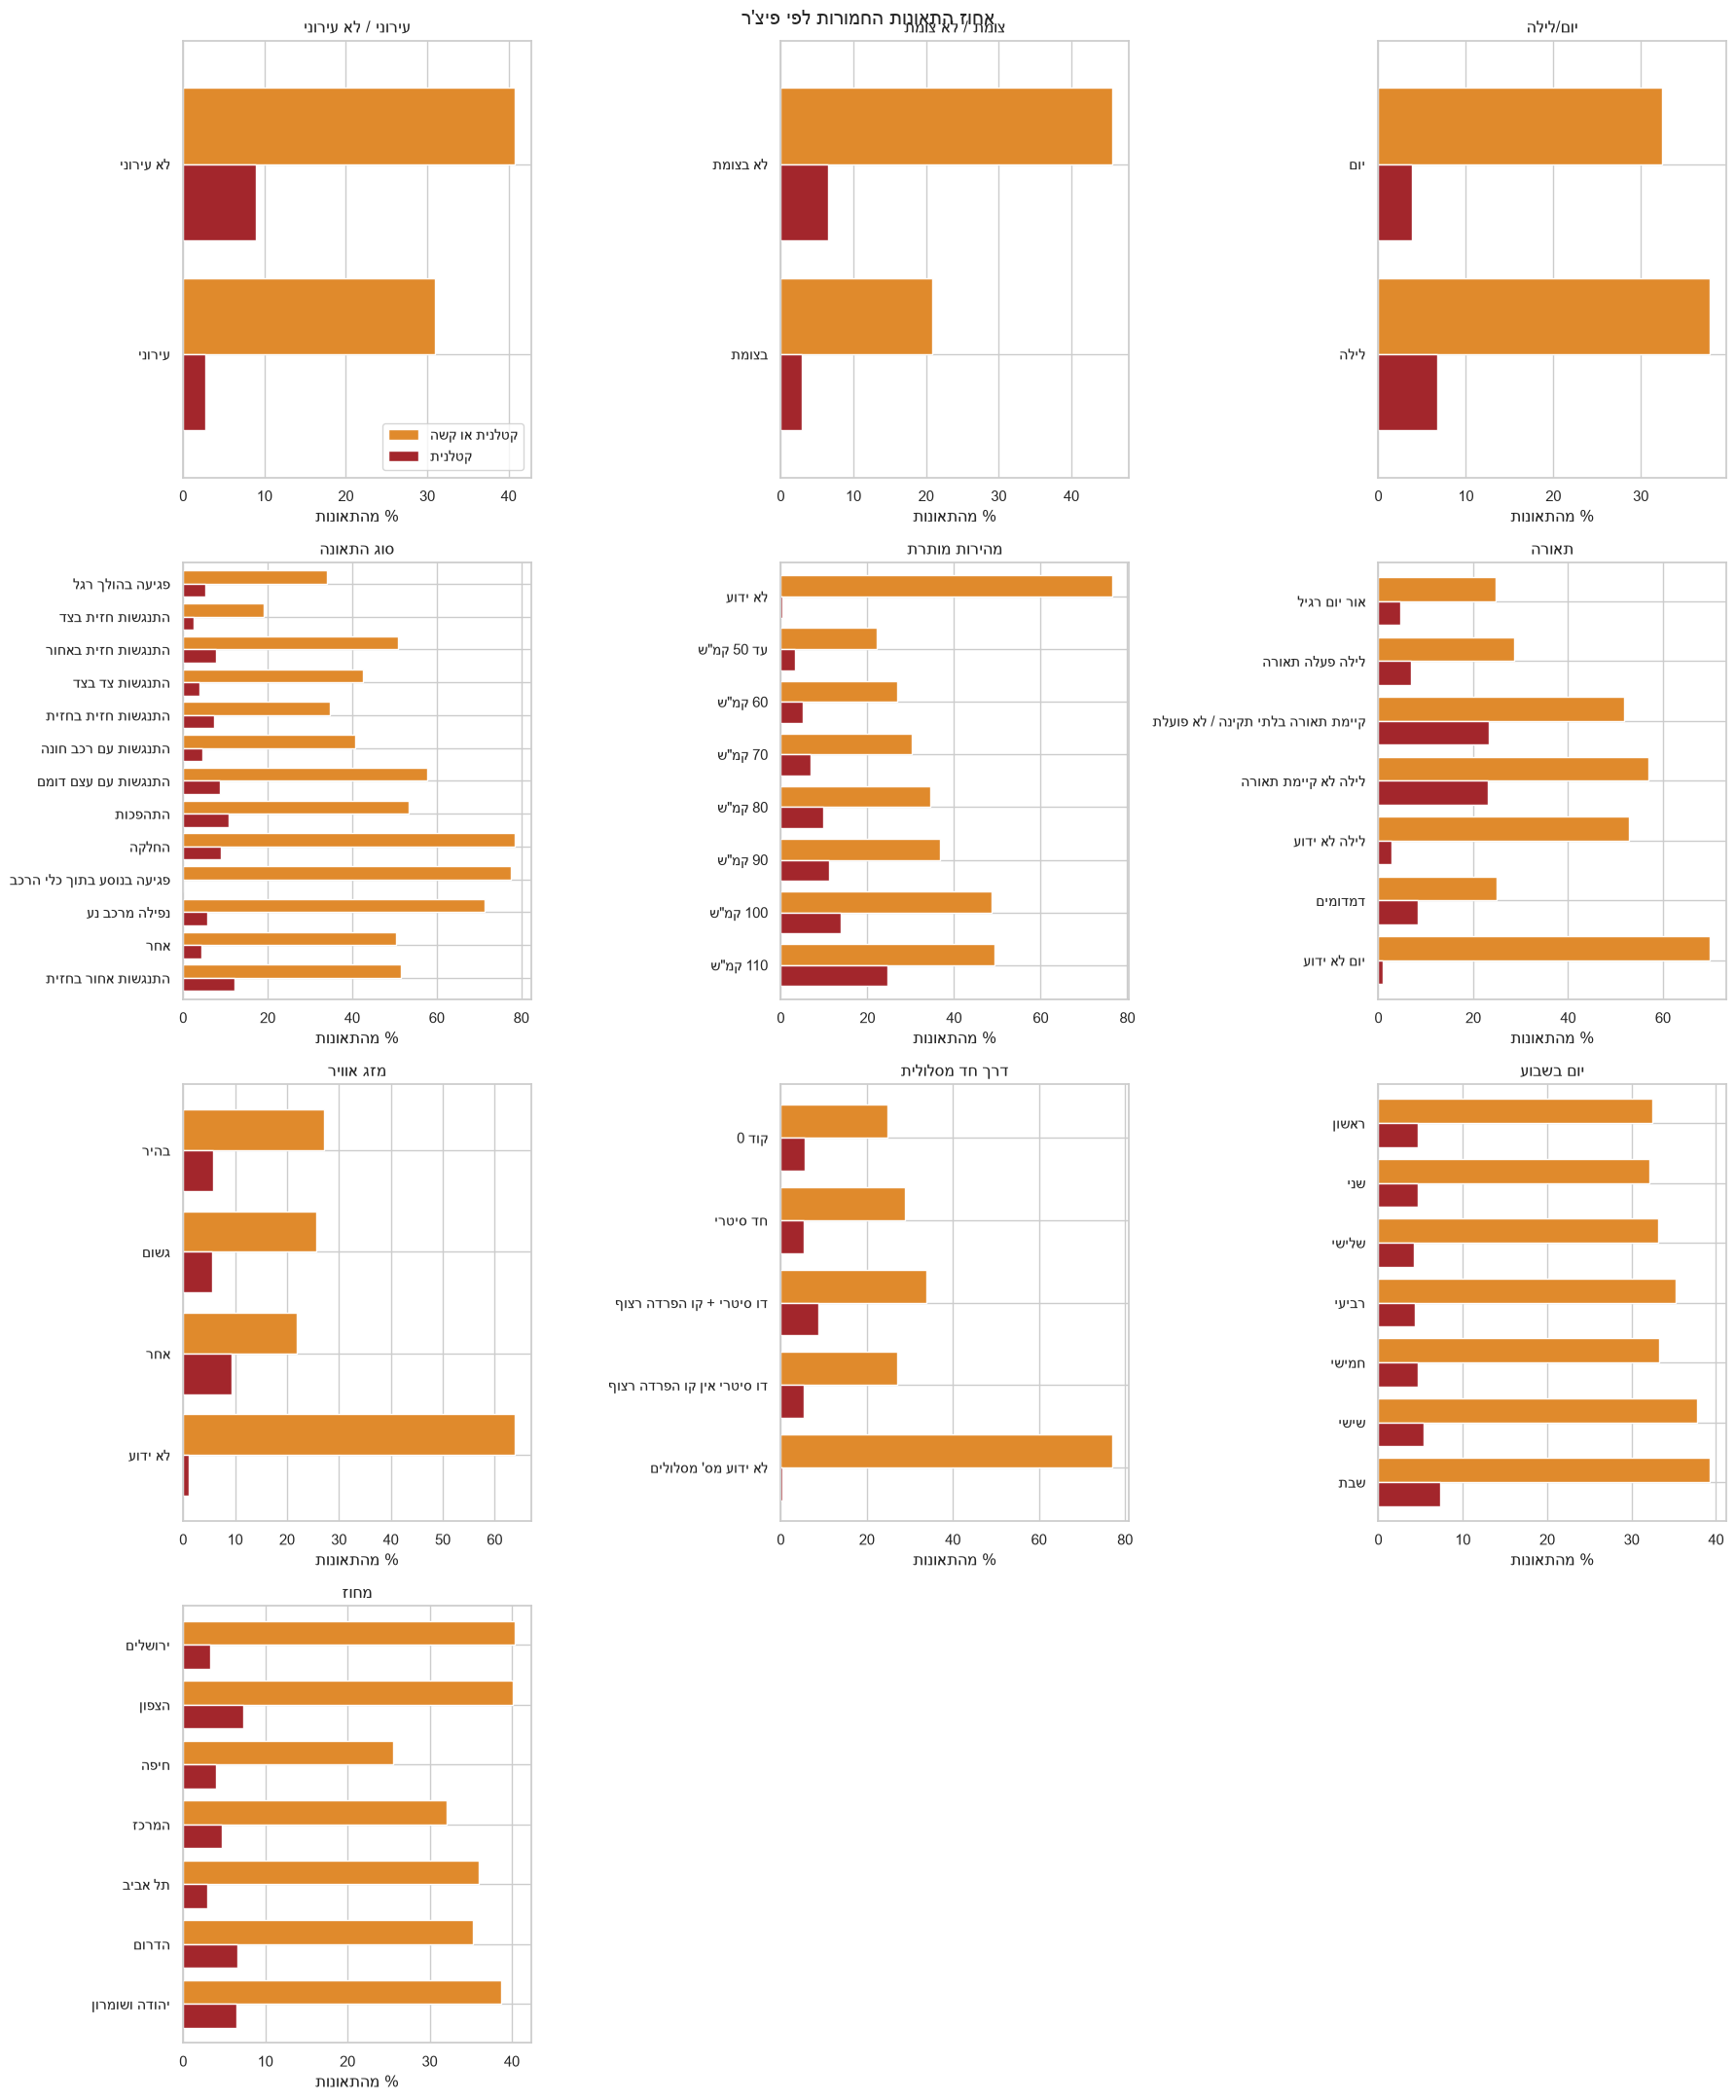

In [7]:
### CODE BY CLAUDE ###
dfe = add_features(df)
dfe["fatal"] = (dfe[TARGET] == 1).astype(int)
dfe["fatal_or_serious"] = (dfe[TARGET] <= 2).astype(int)

def severity_by(col, ax, min_count=30):
    g = dfe.groupby(col).agg(n=("fatal", "size"), fatal=("fatal", "mean"), severe=("fatal_or_serious", "mean"))
    g = g[g["n"] >= min_count]          # בקטגוריה קטנה מאוד האחוזים "רועשים"
    g.index = [label(col, c) for c in g.index]     # שמות מהמילון במקום קודים
    (g[["severe", "fatal"]] * 100).plot.barh(ax=ax, color=["#e08a2c", "#a3262c"], width=0.8, legend=False)
    ax.invert_yaxis()
    ax.set_title(COLUMN_NAMES.get(col, col)); ax.set_xlabel("% מהתאונות"); ax.set_ylabel("")

features = ["URBAN", "JUNCTION", "YOM_LAYLA", "SUG_TEUNA", "MEHIRUT_MUTERET", "TEURA",
            "MEZEG_AVIR", "HAD_MASLUL", "YOM_BASHAVUA", "MAHOZ"]
fig, axes = plt.subplots(4, 3, figsize=(18, 22))
for col, ax in zip(features, axes.ravel()):
    severity_by(col, ax)
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
axes[0, 0].legend(["קטלנית או קשה", "קטלנית"])
fig.suptitle("אחוז התאונות החמורות לפי פיצ'ר")
plt.tight_layout(); plt.savefig(FIGURES / "04_severity_by_feature.png", dpi=150); plt.show()
####

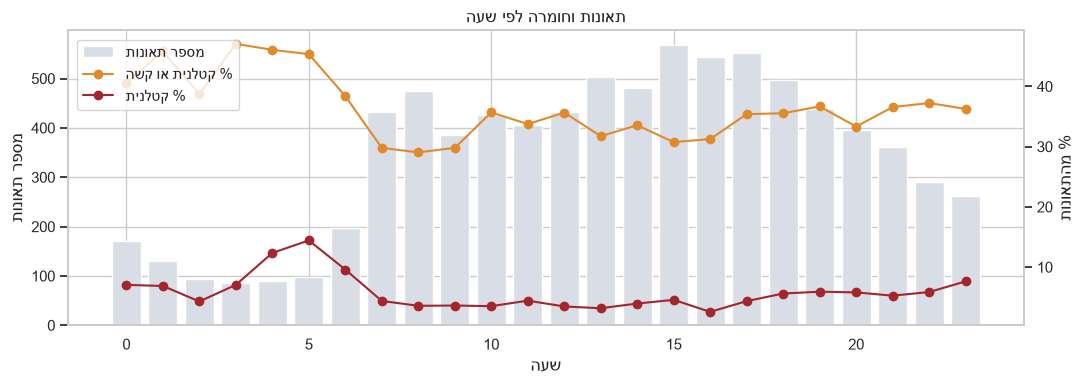

In [8]:
### CODE BY CLAUDE ###
# שעה ביממה (SHAA קובץ לשעות; לאמת את הקידוד במילון)
g = dfe.groupby("HOUR").agg(n=("fatal", "size"), fatal=("fatal", "mean"), severe=("fatal_or_serious", "mean"))
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(g.index, g["n"], color="#d9dee6", label="מספר תאונות")
ax1.set_xlabel("שעה"); ax1.set_ylabel("מספר תאונות")
ax2 = ax1.twinx()
ax2.plot(g.index, g["severe"] * 100, color="#e08a2c", marker="o", label="% קטלנית או קשה")
ax2.plot(g.index, g["fatal"] * 100, color="#a3262c", marker="o", label="% קטלנית")
ax2.set_ylabel("% מהתאונות"); ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
plt.title("תאונות וחומרה לפי שעה")
plt.tight_layout(); plt.savefig(FIGURES / "05_severity_by_hour.png", dpi=150); plt.show()
####

<div dir="rtl">

**מה לחפש בגרפים (לפגישה):**
- האם תאונות בדרך לא־עירונית חמורות יותר מעירוניות?
- האם בלילה אחוז הקטלניות גבוה יותר, למרות שיש פחות תאונות?
- אילו סוגי תאונה הכי קטלניים? (למשל פגיעה בהולך רגל, התנגשות חזית בחזית, התהפכות)
- האם מהירות מותרת גבוהה יותר = חומרה גבוהה יותר?
- השמות בגרפים לקוחים ממילון הקודים של הלמ"ס (`data/raw/codes_dictionary_subset.csv`). קוד שאין לו שם במילון מופיע כ"קוד N".

</div>

<div dir="rtl">

## 5. מיקום: מפת התאונות

</div>

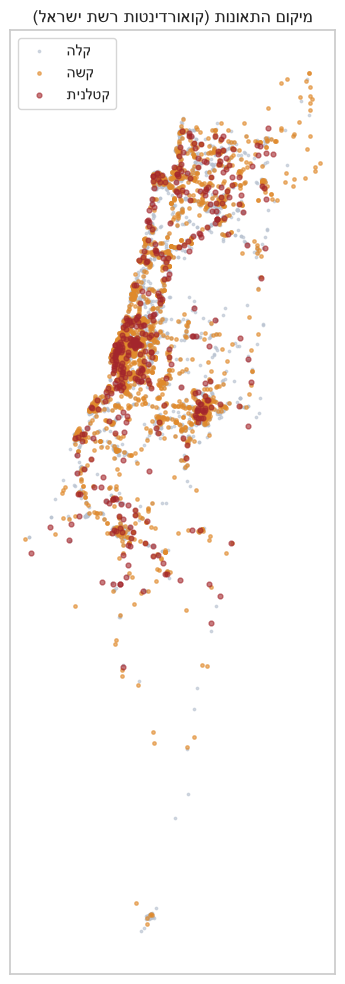

In [9]:
### CODE BY CLAUDE ###
fig, ax = plt.subplots(figsize=(6, 10))
for code_, color, size in [(3, "#b8c2d0", 3), (2, "#e08a2c", 6), (1, "#a3262c", 12)]:
    part = dfe[dfe[TARGET] == code_]
    ax.scatter(part["X"], part["Y"], s=size, c=color, label=SEVERITY_NAMES[code_], alpha=0.6)
ax.set_aspect("equal"); ax.legend(); ax.set_title("מיקום התאונות (קואורדינטות רשת ישראל)")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIGURES / "06_map.png", dpi=150); plt.show()
####

<div dir="rtl">

## 6. בדיקת Data Leakage (שיעור 1): ממצא חשוב
אין בקובץ עמודות של מספר נפגעים. אבל בגרף של סעיף 4 יש משהו חשוד: דווקא הקוד של **"לא ידוע"** בשדות תנאי הדרך
(MEHIRUT_MUTERET = 0, MEZEG_AVIR = 9, HAD_MASLUL = 9) מגיע ל־60%–77% תאונות חמורות, הרבה יותר מכל ערך אמיתי.
בודקים את ערכי "לא ידוע" לפי חומרה:

</div>

In [10]:
### CODE BY CLAUDE ###
unknown = pd.DataFrame({
    "MEHIRUT_MUTERET = 0": df["MEHIRUT_MUTERET"] == 0,
    "PNE_KVISH = 9": df["PNE_KVISH"] == 9,
    "MEZEG_AVIR = 9": df["MEZEG_AVIR"] == 9,
    "TKINUT = 0": df["TKINUT"] == 0,
    "ROHAV = 0": df["ROHAV"] == 0,
})
# אחוז "לא ידוע" בכל עמודה, לפי חומרת התאונה
(unknown.groupby(df[TARGET].map(SEVERITY_NAMES)).mean() * 100).round(0).reindex(SEV_ORDER)
####

,MEHIRUT_MUTERET = 0,PNE_KVISH = 9,MEZEG_AVIR = 9,TKINUT = 0,ROHAV = 0
HUMRAT_TEUNA,,,,,
קטלנית,1.0,1.0,4.0,5.0,4.0
קשה,39.0,39.0,42.0,41.0,42.0
קלה,5.0,7.0,11.0,9.0,12.0


In [11]:
### CODE BY CLAUDE ###
from src.data import details_missing
m = details_missing(df)
print(f"תאונות שבהן כל פרטי הדרך לא ידועים: {m.sum()} ({m.mean():.0%})")
print(pd.crosstab(m.map({True: "חסרים פרטים", False: "יש פרטים"}),
                  df[TARGET].map(SEVERITY_NAMES), normalize="index").mul(100).round(1)[SEV_ORDER])
####

תאונות שבהן כל פרטי הדרך לא ידועים: 1235 (15%)
HUMRAT_TEUNA  קטלנית   קשה   קלה
row_0                           
חסרים פרטים      0.3  76.8  22.8
יש פרטים         5.7  21.2  73.1


<div dir="rtl">

**הממצא:** ב־1,235 תאונות (15%) **כל** שדות תנאי הדרך ריקים יחד, ו־77% מהן "קשות", לעומת 21% בשאר הדאטה.
כנראה אלה תאונות שדווחו בדרך אחרת (בלי תיק חקירה מלא). זה **ארטיפקט של הדיווח**, לא תנאי בדרך:
מודל היה לומד "אם חסרים פרטים, אז קשה", וזה לא עוזר לחזות חומרה של תאונה אמיתית.

**ההחלטה (לדיון בפגישה):** בניסוי הראשי מוציאים את השורות האלה (`get_xy(..., drop_missing_details=True)`) ונשארות 7,080 תאונות.
בניסוי נפרד ב־`02_classification` מראים כמה הארטיפקט "מנפח" את התוצאות כשמשאירים אותן.
⚠️ לאמת במילון / במסמך המתודולוגיה של הלמ"ס מאיפה מגיעות התאונות האלה.

</div>


<div dir="rtl">

## 7. איכות הנתונים (שיעור 3)
בשיעור 3: לפני כל מודל בודקים כפילויות, ערכים חסרים, ועמודות שחוזרות על אותו מידע.

</div>

In [12]:
### CODE BY CLAUDE ###
dups = df.drop(columns=["pk_teuna_fikt"]).duplicated().sum()
print("שורות כפולות (בלי עמודת המזהה):", dups)

xy_missing = df[["X", "Y"]].isna().any(axis=1)
print("תאונות בלי קואורדינטות:", xy_missing.sum())
print(df.loc[xy_missing, "SUG_DEREH"].map(lambda c: label("SUG_DEREH", c)).value_counts())
####

שורות כפולות (בלי עמודת המזהה): 0
תאונות בלי קואורדינטות: 22
SUG_DEREH
לא-עירונית לא בצומת    21
עירונית לא בצומת        1
Name: count, dtype: int64


<div dir="rtl">

**ההחלטות:**
- **כפילויות:** אין. הבדיקה נשארת בקוד (`get_xy`), למקרה שהדאטה יתעדכן.
- **חסרים מבניים** (רחוב, כביש, צומת): לא משלימים, כי לחוסר יש סיבה. במקומם יש דגלים (סעיף 3).
- **חסרים לא מבניים** (‏X ו־Y, כ־20 תאונות): **משלימים בחציון** בתוך ה־Pipeline (`SimpleImputer`), במקום לזרוק את השורות.
  חציון ולא ממוצע, כי הוא לא מושפע מערכים קיצוניים. וה־fit רק על ה־train, כדי שלא יהיה Data Leakage.
- **נרמול ו־PCA:** בודקים ב־`02_classification`, ניסוי 5.

</div>

<div dir="rtl">

## 8. העמודות: מה נשאר, מה יורד, ומה בודקים (פגישת הצוות, 3.11)
הטבלה מסכמת את ההחלטה על כל עמודה. "למודל" = נכנסת לפיצ'רים של `02_classification`.

</div>

In [13]:
### CODE BY CLAUDE ###
from src.data import DROP_NO_INFO, DROP_BY_TEAM, REPLACED, EDA_ONLY

def decision(col):
    if col in DROP_NO_INFO: return "יורדת: אין בה מידע"
    if col in DROP_BY_TEAM: return "יורדת: החלטת הצוות"
    if col in REPLACED: return "מפוצלת ל־URBAN ול־JUNCTION"
    if col == "SHAA": return "הופכת ל־HOUR (שעה)"
    if col in EDA_ONLY: return "נשארת לבדיקה ב־EDA, לא למודל"
    if col == TARGET: return "משתנה המטרה"
    return "למודל"

pd.DataFrame({"עמודה": df.columns, "החלטה": [decision(c) for c in df.columns]}).set_index("עמודה")
####

,החלטה
עמודה,
pk_teuna_fikt,יורדת: אין בה מידע
sug_tik,יורדת: אין בה מידע
THUM_GEOGRAFI,למודל
SUG_DEREH,מפוצלת ל־URBAN ול־JUNCTION
SEMEL_YISHUV,יורדת: החלטת הצוות
REHOV1,"נשארת לבדיקה ב־EDA, לא למודל"
REHOV2,"נשארת לבדיקה ב־EDA, לא למודל"
BAYIT,"נשארת לבדיקה ב־EDA, לא למודל"
ZOMET_IRONI,"נשארת לבדיקה ב־EDA, לא למודל"


<div dir="rtl">

### 8.1 צמתים: מאחדים לעמודה אחת
`ZOMET_IRONI` (צומת בעיר) ו־`ZOMET_LO_IRONI` (צומת בין־עירוני) מאוחדות לעמודה אחת, `ZOMET`.

</div>

In [14]:
### CODE BY CLAUDE ###
both = (df["ZOMET_IRONI"].notna() & df["ZOMET_LO_IRONI"].notna()).sum()
print("תאונות ששתי עמודות הצומת מלאות בהן:", both)
print("תאונות עם קוד צומת:", dfe["ZOMET"].notna().sum(), "| צמתים שונים:", dfe["ZOMET"].nunique())
print("הצומת עם הכי הרבה תאונות:", dfe["ZOMET"].value_counts().max(), "תאונות")
print("צמתים עם תאונה אחת בלבד:", (dfe["ZOMET"].value_counts() == 1).sum())
# האם קוד של צומת עירוני ייחודי בכל הארץ, או חוזר בכמה יישובים?
cities = df.dropna(subset=["ZOMET_IRONI"]).groupby("ZOMET_IRONI")["SEMEL_YISHUV"].nunique()
print("קודי צומת עירוני שמופיעים ביותר מיישוב אחד:", (cities > 1).sum(), "| מקסימום יישובים לקוד אחד:", cities.max())
print()
print("קוד צומת מלא, לפי סוג הדרך:")
print(pd.crosstab(df["SUG_DEREH"].map(lambda c: label("SUG_DEREH", c)), dfe["ZOMET"].notna().map({True: "יש קוד", False: "אין קוד"})))
####

תאונות ששתי עמודות הצומת מלאות בהן: 0
תאונות עם קוד צומת: 3750 | צמתים שונים: 2344
הצומת עם הכי הרבה תאונות: 14 תאונות
צמתים עם תאונה אחת בלבד: 1606
קודי צומת עירוני שמופיעים ביותר מיישוב אחד: 47 | מקסימום יישובים לקוד אחד: 7

קוד צומת מלא, לפי סוג הדרך:
ZOMET                אין קוד  יש קוד
SUG_DEREH                           
לא-עירונית בצומת           1    1239
לא-עירונית לא בצומת     1628       0
עירונית בצומת             34    2511
עירונית לא בצומת        2902       0


<div dir="rtl">

### 8.2 רחוב ומספר בית: יש שם משהו מעניין?

</div>

In [15]:
### CODE BY CLAUDE ###
print("רחוב (REHOV1) מלא:", df["REHOV1"].notna().sum(), "| רחובות שונים:", df["REHOV1"].nunique())
streets = df.dropna(subset=["REHOV1"]).groupby("REHOV1")["SEMEL_YISHUV"].nunique()
print("קוד רחוב אחד מופיע בעד", streets.max(), "יישובים שונים")
print("רחוב שני (REHOV2) מלא:", df["REHOV2"].notna().sum(),
      "| מתוכן בצומת:", (df["REHOV2"].notna() & dfe["JUNCTION"].eq(1)).sum())
print()
# הרחובות עם הכי הרבה תאונות: יישוב + רחוב (שמות הרחובות לא במילון, רק קודים)
top = (dfe.dropna(subset=["REHOV1"]).groupby(["SEMEL_YISHUV", "REHOV1"])
       .agg(תאונות=("fatal", "size"), אחוז_חמורות=("fatal_or_serious", "mean")))
top = top.sort_values("תאונות", ascending=False).head(8)
top["אחוז_חמורות"] = (top["אחוז_חמורות"] * 100).round(0)
top.index = [f"{label('SEMEL_YISHUV', s)}, רחוב {int(r)}" for s, r in top.index]
top
####

רחוב (REHOV1) מלא: 5171 | רחובות שונים: 1181
קוד רחוב אחד מופיע בעד 38 יישובים שונים
רחוב שני (REHOV2) מלא: 2511 | מתוכן בצומת: 2511



,תאונות,אחוז_חמורות
"קרית ים, רחוב 161",27,11.0
"כפר סבא, רחוב 523",24,12.0
"ירושלים, רחוב 4452",21,38.0
"ירושלים, רחוב 1714",20,25.0
"תל אביב - יפו, רחוב 1994",20,40.0
"תל אביב - יפו, רחוב 1555",19,42.0
"אשדוד, רחוב 206",17,29.0
"רחובות, רחוב 403",17,59.0


In [16]:
### CODE BY CLAUDE ###
bayit = df["BAYIT"]
print("מספר בית מלא:", bayit.notna().sum(), "תאונות, מתוכן 9999 (לא ידוע):", (bayit == 9999).sum())
print("מספר בית מלא, לפי סוג הדרך:")
print(pd.crosstab(df["SUG_DEREH"].map(lambda c: label("SUG_DEREH", c)), bayit.notna()))
known = dfe[bayit.notna()].assign(ידוע=lambda d: d["BAYIT"].ne(9999).map({True: "מספר ידוע", False: "9999 (לא ידוע)"}))
print()
print(pd.crosstab(known["ידוע"], known[TARGET].map(SEVERITY_NAMES), normalize="index").mul(100).round(1)[SEV_ORDER])
####

מספר בית מלא: 2902 תאונות, מתוכן 9999 (לא ידוע): 1517
מספר בית מלא, לפי סוג הדרך:
BAYIT                False  True 
SUG_DEREH                        
לא-עירונית בצומת      1240      0
לא-עירונית לא בצומת   1628      0
עירונית בצומת         2545      0
עירונית לא בצומת         0   2902

HUMRAT_TEUNA    קטלנית   קשה   קלה
ידוע                              
9999 (לא ידוע)     2.8  45.9  51.4
מספר ידוע          3.3  30.8  65.8


<div dir="rtl">

### 8.3 שעה: מה המשמעות של `SHAA`

</div>

In [17]:
### CODE BY CLAUDE ###
hours = pd.read_csv(Path.cwd().parent / "data" / "raw" / "codes_dictionary_subset.csv")
print("מילון הקודים, טבלה 93 (שעות), דוגמאות:")
print(hours[hours["MS_TAVLA"] == 93][["KOD", "TEUR"]].to_string(index=False))
print("\nערכים ב־SHAA:", df["SHAA"].min(), "עד", df["SHAA"].max(), "|", df["SHAA"].nunique(), "ערכים שונים")
check = dfe[["SHAA", "HOUR"]].drop_duplicates().sort_values("SHAA")
print("דוגמה להמרה SHAA → HOUR:")
print(check[check["SHAA"].isin([1, 4, 5, 8, 33, 96])].to_string(index=False))
####

מילון הקודים, טבלה 93 (שעות), דוגמאות:
 KOD        TEUR
   1 00:00-00:14
   4 00:45-00:59
   5 01:00-01:14
  96 23:45-23:59

ערכים ב־SHAA: 1 עד 96 | 96 ערכים שונים
דוגמה להמרה SHAA → HOUR:
 SHAA  HOUR
    1     0
    4     0
    5     1
    8     1
   33     8
   96    23


<div dir="rtl">

### 8.4 מחוז, נפה ואזור טבעי

</div>

In [18]:
### CODE BY CLAUDE ###
print("מחוזות:", df["MAHOZ"].nunique(), "| נפות:", df["NAFA"].nunique(), "| אזורים טבעיים:", df["EZOR_TIVI"].nunique())
print("שתי הספרות הראשונות של האזור הטבעי = קוד הנפה:", (df["EZOR_TIVI"] // 10 == df["NAFA"]).all())
print("קודים של אזור טבעי שאין להם שם במילון:", sorted(set(df["EZOR_TIVI"]) - set(hours[hours["MS_TAVLA"] == 80]["KOD"])))
print()
# דוגמה להיררכיה: מחוז המרכז
center = df[df["MAHOZ"] == 4].groupby(["NAFA", "EZOR_TIVI"]).size().rename("תאונות").reset_index()
center["נפה"] = center["NAFA"].map(lambda c: label("NAFA", c))
center["אזור טבעי"] = center["EZOR_TIVI"].map(lambda c: label("EZOR_TIVI", c))
print("דוגמה, מחוז המרכז:")
print(center[["נפה", "אזור טבעי", "תאונות"]].to_string(index=False))
####

מחוזות: 8 | נפות: 17 | אזורים טבעיים: 54
שתי הספרות הראשונות של האזור הטבעי = קוד הנפה: True
קודים של אזור טבעי שאין להם שם במילון: [214, 777, 999]

דוגמה, מחוז המרכז:
      נפה        אזור טבעי  תאונות
    השרון       מערב השרון     360
    השרון       מזרח השרון     100
פתח תקווה       דרום השרון     332
פתח תקווה   אזור פתח תקווה     572
     רמלה     אזור מודיעין      57
     רמלה        אזור רמלה     209
   רחובות      אזור רחובות     190
   רחובות אזור ראשון לציון     235


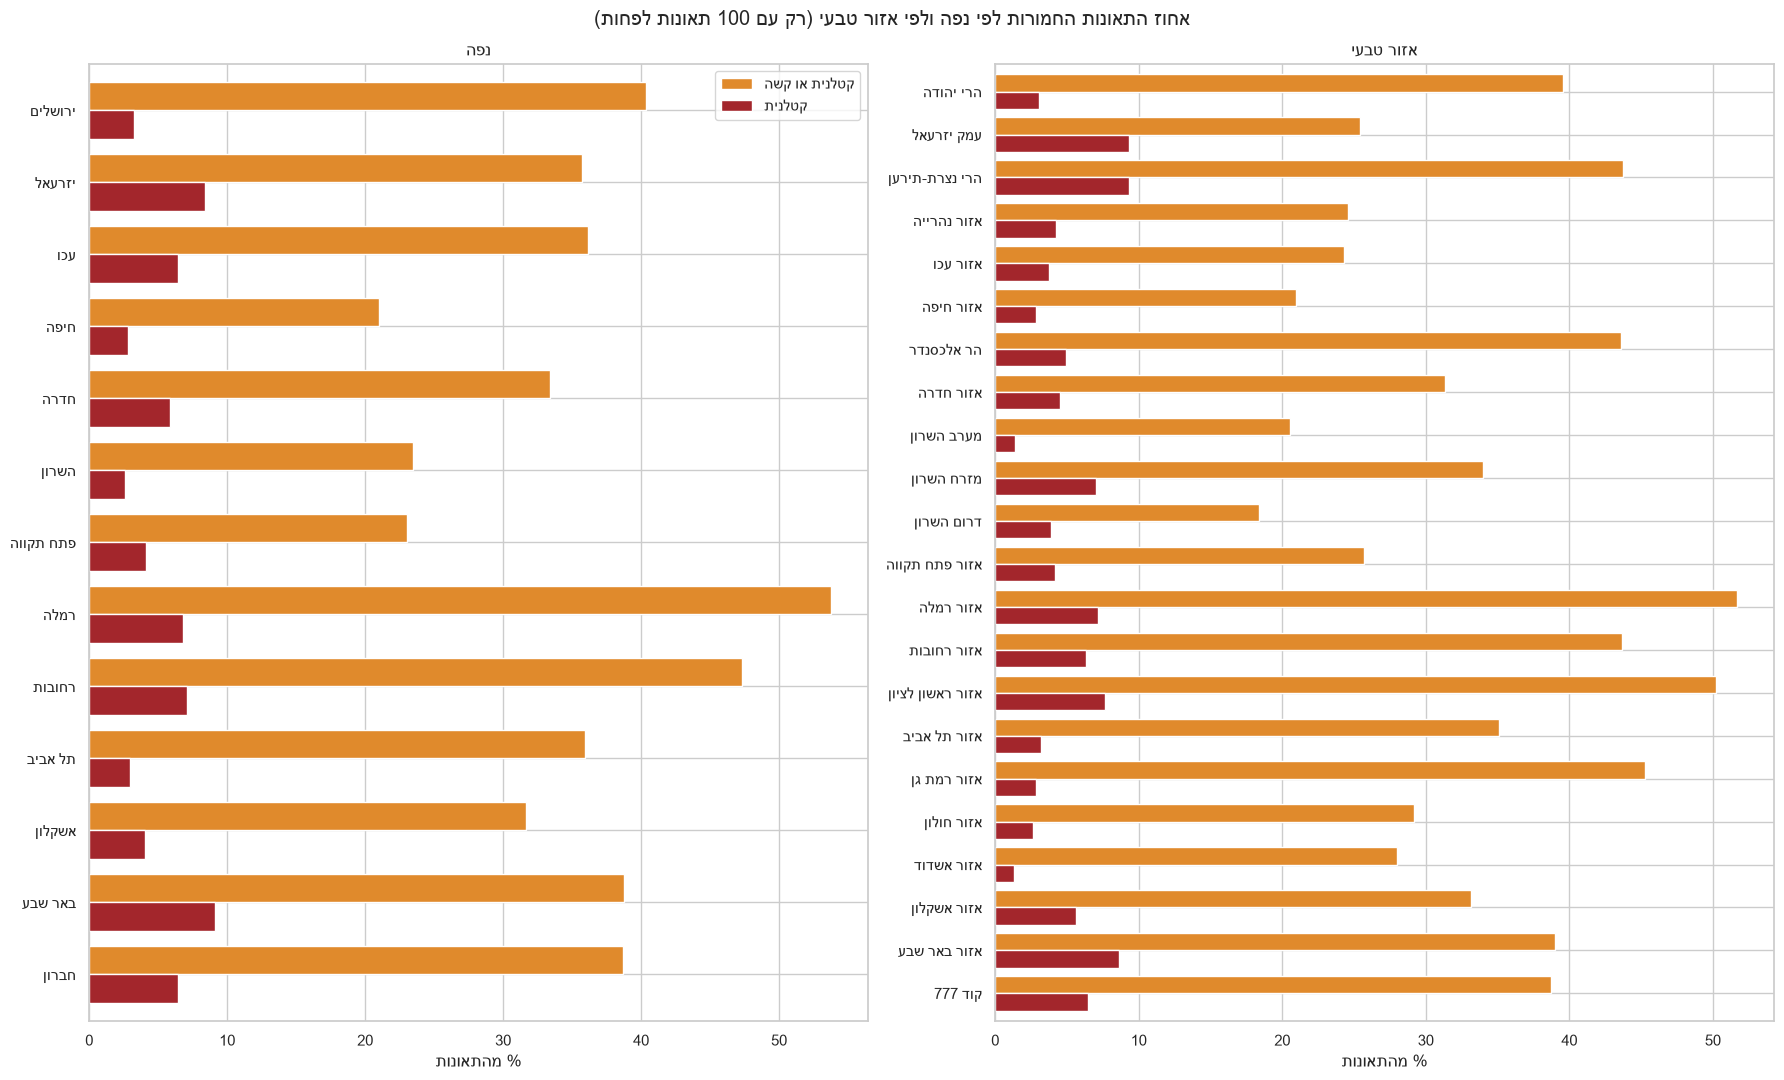

In [19]:
### CODE BY CLAUDE ###
fig, axes = plt.subplots(1, 2, figsize=(18, 11))
severity_by("NAFA", axes[0], min_count=100)
severity_by("EZOR_TIVI", axes[1], min_count=100)
axes[0].legend(["קטלנית או קשה", "קטלנית"])
fig.suptitle("אחוז התאונות החמורות לפי נפה ולפי אזור טבעי (רק עם 100 תאונות לפחות)")
plt.tight_layout(); plt.savefig(FIGURES / "07_severity_by_region.png", dpi=150); plt.show()
####

<div dir="rtl">

**המסקנות מסעיף 8:**
- **צמתים:** אחרי האיחוד יש 3,750 תאונות עם קוד צומת, ב־2,344 צמתים שונים. 1,606 צמתים מופיעים פעם אחת בלבד, והצומת הכי "עמוס" מופיע 14 פעמים.
  One-hot שלה היה יוצר יותר מ־2,000 עמודות כמעט ריקות, ולכן `ZOMET` לא נכנסת למודל. את המידע "האם בצומת" כבר נותן הדגל `JUNCTION`: קוד צומת מלא כמעט רק כש־`SUG_DEREH` אומרת "בצומת".
  ⚠️ קוד של צומת עירוני חוזר בכמה יישובים (47 קודים, עד 7 יישובים לקוד). כלומר בלי היישוב, הקוד לבד לא מזהה צומת אחד.
- **רחוב:** אותו דבר: 1,181 קודים, וקוד רחוב אחד מופיע בעד 38 יישובים, כי הקוד הוא של רחוב **בתוך** יישוב. ברחוב עם הכי הרבה תאונות יש 27, מעט מדי כדי ללמוד ממנו. שמות הרחובות לא נמצאים במילון.
  `REHOV2` מלאה רק בתאונות בצומת (הרחוב השני של הצומת).
- **מספר בית:** מלא רק בתאונה עירונית שלא בצומת, ובחצי מהמקרים הוא 9999 (לא ידוע). בטבלה נראה ש־"לא ידוע" חמור יותר (46% קשות מול 31%),
  אבל רוב ההבדל מגיע מהארטיפקט של סעיף 6: אחרי שמוציאים את התאונות בלי פרטי דרך, נשאר 25% מול 23%. אין כאן מידע מעניין למודל.
- **שעה:** `SHAA` היא **רבע שעה** ביממה: 96 קודים, 1 = 00:00–00:14 ו־96 = 23:45–23:59 (טבלה 93 במילון). מקבצים ארבעה רבעים לשעה אחת: `HOUR` = 0 עד 23.
- **מחוז, נפה, אזור טבעי:** זו חלוקה גאוגרפית של הלמ"ס בשלוש רמות, מהגדולה לקטנה. **מחוז** (8 בדאטה) מתחלק ל**נפות** (17), וכל נפה מתחלקת ל**אזורים טבעיים** (54):
  אזורים שדומים בנוף, באקלים ובאופי היישובים, למשל "הרי יהודה" ו"שפלת יהודה" בנפת ירושלים. הקוד של אזור טבעי הוא קוד הנפה ועוד ספרה (‏422 = אזור פתח תקווה, בנפת פתח תקווה).
  שלושה קודים בלי שם במילון: 777 (‏403 תאונות, יהודה ושומרון), 999 (‏21, לא ידוע), 214 (‏4).
  בגרף יש הבדלים גדולים בין אזורים: למשל ברמלה ובראשון לציון כ־50% מהתאונות חמורות, ובדרום השרון ובמערב השרון כ־20%. לכן `EZOR_TIVI` נכנסת למודל.

</div>

<div dir="rtl">

## סיכום ה־EDA
1. 8,315 תאונות ו־45 עמודות. אחרי הניקוי: 28 קטגוריות, 2 מספריות (X, Y), ו־4 דגלים: יותר מ־15 פיצ'רים משמעותיים.
2. הדאטה לא מאוזן: 4.9% קטלניות (5.7% אחרי הוצאת השורות בלי פרטים).
3. החסרים בעמודות המיקום מבניים, תלויים בסוג הדרך. סוג הדרך מפוצל לשני דגלים: עירוני, ובצומת.
4. צמתים, רחובות ומספרי בית: מזהים עם הרבה ערכים ומעט תאונות לכל אחד, ולכן נשארים רק ל־EDA. אזור טבעי נכנס למודל (סעיף 8).
5. 15% מהתאונות בלי פרטי דרך בכלל, ורובן "קשות": ארטיפקט שמוציאים מהניסוי הראשי.
6. המשך: `02_classification.ipynb`.

</div>